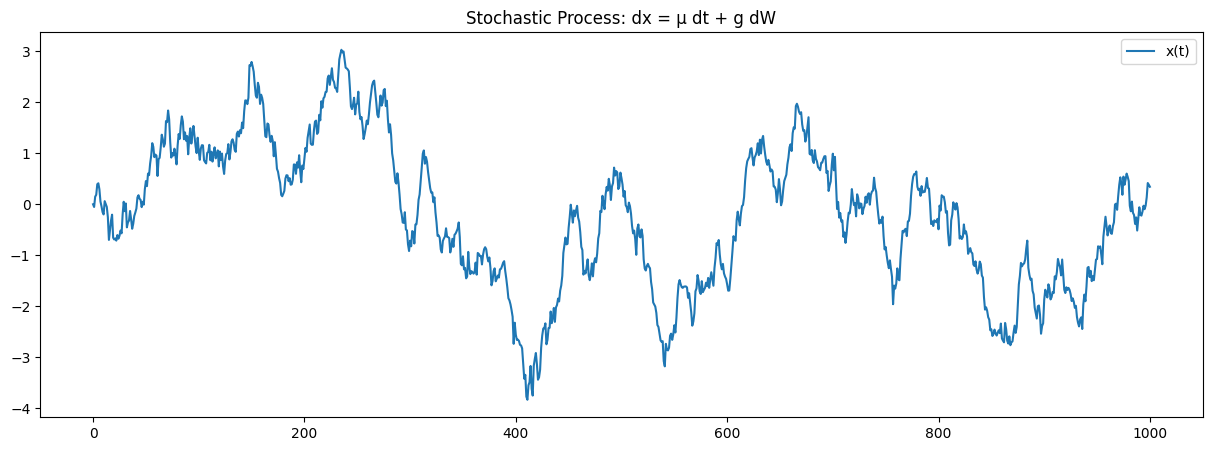

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.preprocessing import MinMaxScaler

# Random Walk
g = 0.2       # Diffusion coefficient
T = 1000.0    
N = 1000      
dt = T / N    # Time step size
x0 = 0.0      
mu = np.sin(dt/T)  # Drift coefficient

t = np.linspace(0, T, N+1)
dW = np.random.normal(0.0, np.sqrt(dt), N)
W = np.concatenate(([0], np.cumsum(dW)))

x = np.zeros(N+1)
x[0] = x0
for i in range(1, N+1):
    x[i] = x[i-1] + mu*dt + g*dW[i-1]

plt.figure(figsize=(15,5))
plt.plot(t, x, label="x(t)")
plt.title("Stochastic Process: dx = μ dt + g dW")
plt.legend()
plt.show()

In [17]:
def create_dataset(series, window_size=20):
    X, y = [], []
    for i in range(len(series)-window_size):
        X.append(series[i:i+window_size])
        y.append(series[i+window_size])  # predict next step
    return np.array(X), np.array(y)

scaler = MinMaxScaler(feature_range=(-1, 1))
x_scaled = scaler.fit_transform(x.reshape(-1, 1))

window_size = 25
X, y = create_dataset(x_scaled, window_size)

# reshape for LSTM: [samples, time steps, features]
X = X.reshape((X.shape[0], X.shape[1], 1))

# train/test split
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# LSTM Model

In [18]:
model = Sequential()
model.add(LSTM(50, activation="tanh", input_shape=(window_size, 1)))
model.add(Dense(1))
model.compile(optimizer="adam", loss="mse")

history = model.fit(X_train, y_train, epochs=20, batch_size=32,
                    validation_data=(X_test, y_test), verbose=1)

Epoch 1/20
25/25 [==============================] - 2s 26ms/step - loss: 0.0950 - val_loss: 0.0306
Epoch 2/20
25/25 [==============================] - 0s 11ms/step - loss: 0.0225 - val_loss: 0.0161
Epoch 3/20
25/25 [==============================] - 0s 10ms/step - loss: 0.0160 - val_loss: 0.0134
Epoch 4/20
25/25 [==============================] - 0s 10ms/step - loss: 0.0131 - val_loss: 0.0114
Epoch 5/20
25/25 [==============================] - 0s 10ms/step - loss: 0.0116 - val_loss: 0.0105
Epoch 6/20
25/25 [==============================] - 0s 10ms/step - loss: 0.0105 - val_loss: 0.0099
Epoch 7/20
25/25 [==============================] - 0s 8ms/step - loss: 0.0095 - val_loss: 0.0091
Epoch 8/20
25/25 [==============================] - 0s 8ms/step - loss: 0.0089 - val_loss: 0.0085
Epoch 9/20
25/25 [==============================] - 0s 9ms/step - loss: 0.0081 - val_loss: 0.0081
Epoch 10/20
25/25 [==============================] - 0s 9ms/step - loss: 0.0078 - val_loss: 0.0077
Epoch 11/20
2

7/7 [==============================] - 0s 2ms/step


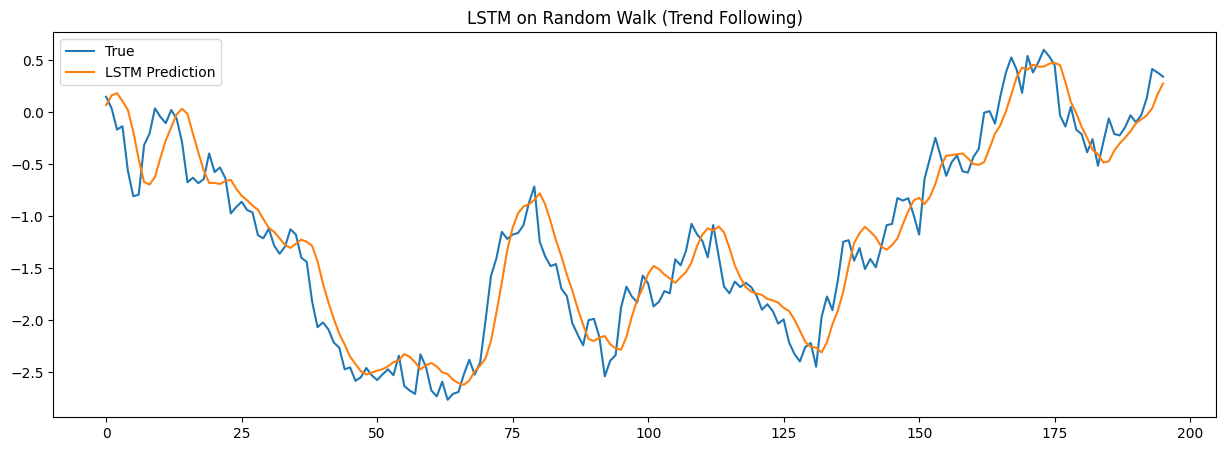

In [19]:
y_pred = model.predict(X_test)
y_pred_inv = scaler.inverse_transform(y_pred)
y_test_inv = scaler.inverse_transform(y_test.reshape(-1, 1))

plt.figure(figsize=(15,5))
plt.plot(range(len(y_test_inv)), y_test_inv, label="True")
plt.plot(range(len(y_pred_inv)), y_pred_inv, label="LSTM Prediction")
plt.title("LSTM on Random Walk (Trend Following)")
plt.legend()
plt.show()


In [20]:

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

In [21]:
# Prepare dataset
seq_length = 25  # window size

def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i + seq_length])
        y.append(data[i + seq_length])
    return np.array(X), np.array(y)

scaler = MinMaxScaler()
x_scaled = scaler.fit_transform(x.reshape(-1, 1)).flatten()

X, y = create_sequences(x_scaled, seq_length)

# Convert to tensors
X_tensor = torch.tensor(X, dtype=torch.float32).unsqueeze(-1)  # shape: [samples, seq_length, 1]
y_tensor = torch.tensor(y, dtype=torch.float32)                # shape: [samples]

# Train/test split
split = int(0.8 * len(X_tensor))
X_train_2, X_test_2 = X_tensor[:split], X_tensor[split:]
y_train_2, y_test_2 = y_tensor[:split], y_tensor[split:]

# Masked Transformer Model

In [22]:
class MaskedTransformer(nn.Module):
    def __init__(self, input_dim, embed_dim, num_heads, num_layers, hidden_dim):
        super().__init__()
        self.embedding = nn.Linear(input_dim, embed_dim)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, 
            nhead=num_heads, 
            dim_feedforward=hidden_dim,
            batch_first=True  # important: use batch-first convention
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc = nn.Linear(embed_dim, 1)
    
    def forward(self, x):
        # x shape: [batch, seq_len, input_dim]
        x = self.embedding(x)                  # -> [batch, seq_len, embed_dim]
        x = self.transformer(x)                # -> [batch, seq_len, embed_dim]
        x = self.fc(x[:, -1, :])               # predict last step
        return x.squeeze()

model = MaskedTransformer(
    input_dim=1, embed_dim=64, num_heads=4, num_layers=3, hidden_dim=128
)


In [23]:
def train_model(model, X_train_2, y_train_2, epochs=50, lr=0.001):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        y_pred_2 = model(X_train_2)
        loss = criterion(y_pred_2, y_train_2)
        loss.backward()
        optimizer.step()
        
        if epoch % 10 == 0:
            print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

train_model(model, X_train_2, y_train_2, epochs=50)

Epoch 0, Loss: 0.1972
Epoch 10, Loss: 0.1062
Epoch 20, Loss: 0.0255
Epoch 30, Loss: 0.0211
Epoch 40, Loss: 0.0097


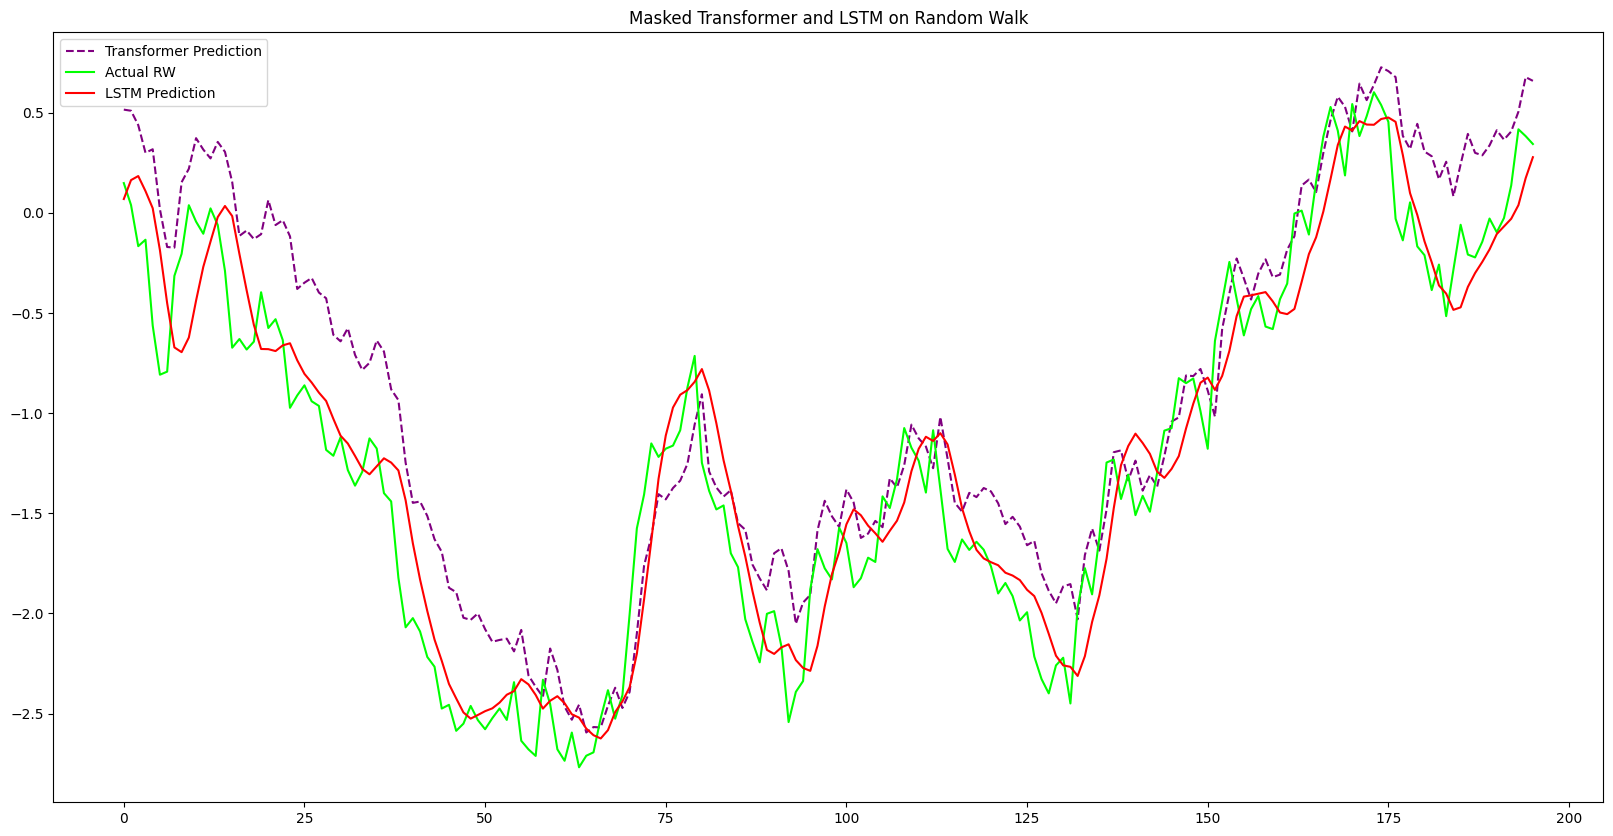

In [24]:
model.eval()
with torch.no_grad():
    y_pred_2 = model(X_test_2).numpy()

# Inverse scaling
y_pred_inv_2 = scaler.inverse_transform(y_pred_2.reshape(-1, 1)).flatten()
y_test_inv_2 = scaler.inverse_transform(y_test_2.numpy().reshape(-1, 1)).flatten()



plt.figure(figsize=(20,10))
#plt.plot(y_test_inv_2, label="Actual RW")
plt.plot(y_pred_inv_2, label="Transformer Prediction", linestyle='dashed', color="purple")
plt.plot(range(len(y_test_inv)), y_test_inv, label="Actual RW", color="lime")
plt.plot(range(len(y_pred_inv)), y_pred_inv, label="LSTM Prediction", color="red")
plt.title("Masked Transformer and LSTM on Random Walk")
plt.legend()
plt.show()

In [25]:
from sklearn.metrics import mean_squared_error
import numpy as np


# Calculate error metrics
mse_lstm = mean_squared_error(y_test_inv, y_pred_inv)
rmse_lstm = np.sqrt(mse_lstm)

mse_masked_transformer = mean_squared_error(y_test_inv_2, y_pred_inv_2)
rmse_masked_transformer = np.sqrt(mse_masked_transformer)

print(f"MSE_LSTM: {mse_lstm:.4f}")
print(f"RMSE_LSTM: {rmse_lstm:.4f}")
print(f"MSE_Masked_Transformer: {mse_masked_transformer:.4f}")
print(f"RMSE_Masked_transromer: {rmse_masked_transformer:.4f}")

MSE_LSTM: 0.0689
RMSE_LSTM: 0.2624
MSE_Masked_Transformer: 0.1645
RMSE_Masked_transromer: 0.4056


# Linear Regression as Baseline Model

MSE_Baseline: 0.9673, RMSE_Baseline: 0.9835
MSE_LSTM: 0.0689, RMSE_LSTM: 0.2624
MSE_Masked_Transformer: 0.1645, RMSE_Masked_Transformer: 0.4056


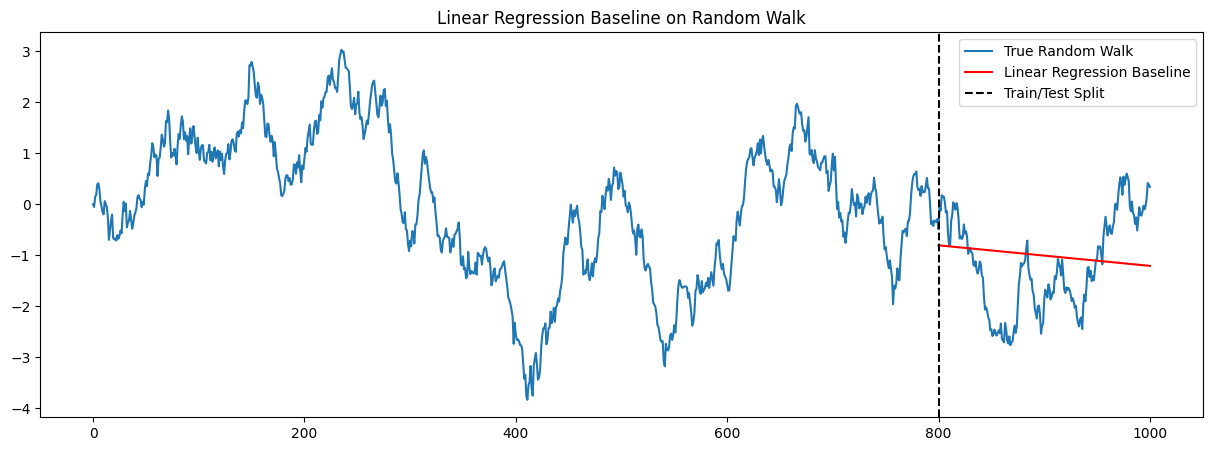

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error


time_idx = np.arange(len(x)).reshape(-1, 1)  # feature: time
values = x.reshape(-1, 1)                    # target: process values


split = int(len(x) * 0.8)
X_train_bs, X_test__bs = time_idx[:split], time_idx[split:]
y_train_bs, y_test_bs = values[:split], values[split:]


lin_reg = LinearRegression()
lin_reg.fit(X_train_bs, y_train_bs)

# Predictions
y_pred_bs = lin_reg.predict(X_test__bs)

# Error metrics
mse_bs = mean_squared_error(y_test_bs, y_pred_bs)
rmse_bs = np.sqrt(mse_bs)

print(
    f"MSE_Baseline: {mse_bs:.4f}, RMSE_Baseline: {rmse_bs:.4f}\n"
    f"MSE_LSTM: {mse_lstm:.4f}, RMSE_LSTM: {rmse_lstm:.4f}\n"
    f"MSE_Masked_Transformer: {mse_masked_transformer:.4f}, RMSE_Masked_Transformer: {rmse_masked_transformer:.4f}"
)


plt.figure(figsize=(15,5))
plt.plot(time_idx, values, label="True Random Walk")
plt.plot(X_test__bs, y_pred_bs, label="Linear Regression Baseline", color="red")
plt.axvline(split, color="black", linestyle="--", label="Train/Test Split")
plt.title("Linear Regression Baseline on Random Walk")
plt.legend()
plt.show()


#  Drift baseline -> MSE: 0.0450, RMSE: 0.2121

# Drift Baseline Model

In [29]:
import numpy as np
from sklearn.metrics import mean_squared_error

train = x[:split]
test  = x[split:]

# estimate drift mu_hat from TRAIN increments
mu_hat = np.mean(np.diff(train))

# one-step-ahead predictions on the TEST: y_{t+1} = y_t + mu_hat
# align shapes: we predict from test[:-1] to compare with test[1:]
y_pred_drift = test[:-1] + mu_hat
y_true_1 = test[1:]

mse_drift = mean_squared_error(y_true_1, y_pred_drift)
rmse_drift = np.sqrt(mse_drift)
print(f"Drift baseline -> MSE: {mse_drift:.4f}, RMSE: {rmse_drift:.4f}")


Drift baseline -> MSE: 0.0364, RMSE: 0.1909
